In [1]:
import emcee
import corner
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import pickle
from uncertainties import ufloat
from uncertainties.umath import *
from uncertainties import unumpy as unp
from astropy import units as u
from astropy.cosmology import FlatLambdaCDM
cosmo=FlatLambdaCDM(70, 0.3)
from statistics_functions import chi_squared
from load_data_and_var import generate_nfws_from_combined_dataset_werr

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
with open('data/mcxc_psz_combined.pkl', 'rb') as f:
    combined_data = pickle.load(f)
low_z_data = combined_data[combined_data['z_y'] < 0.2][combined_data['Sub-Cat']=='REFLEX'][['OName','AName', 'L500', 'z_y']].rename(columns={'AName': 'Name'}).dropna()

/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_23094/3620387234.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  low_z_data = combined_data[combined_data['z_y'] < 0.2][combined_data['Sub-Cat']=='REFLEX'][['OName','AName', 'L500', 'z_y']].rename(columns={'AName': 'Name'}).dropna()


In [3]:
low_z_data

,OName,Name,L500,z_y
2,RXCJ0003.8+0203,A2700,0.846881,0.0924
3,RXCJ0006.0-3443,A2721,1.809494,0.1147
6,RXCJ0011.3-2851,A2734,1.086002,0.0620
9,RXCJ0013.6-1930,A0013,1.236332,0.0940
10,RXCJ0014.3-6604,A2746,2.827248,0.1599
...,...,...,...,...
541,RXCJ2344.2-0422,,1.852614,0.0786
543,RXCJ2347.7-2808,A4038,1.029501,0.0300
547,RXCJ2354.2-1024,A2670,1.336537,0.0765
549,RXCJ2357.0-3445,A4059,1.629622,0.0475


In [4]:
reflex_data = pd.read_csv('data/reflex70.txt', header=7, sep='|', skiprows=[range(6), 8],on_bad_lines='warn', skipfooter=1, skipinitialspace=True).rename(columns=lambda x: x.strip())
#data = data.apply(lambda x: x.str.strip() if x.dtype == 'object' else x)
#data['Name'].values.strip()
reflex_data = reflex_data.apply(lambda x: x.str.strip() if x.dtype == 'object' else x)[['RXC', 'Flux', 'e_Flux', 'ObsLum', 'LumCor', 'z']].dropna()

/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_23094/2434024660.py:1: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.
  reflex_data = pd.read_csv('data/reflex70.txt', header=7, sep='|', skiprows=[range(6), 8],on_bad_lines='warn', skipfooter=1, skipinitialspace=True).rename(columns=lambda x: x.strip())


In [69]:
reflex_data

,RXC,Flux,e_Flux,ObsLum,LumCor,z
0,RXCJ0003.1-0605,4.497,12.4,6.395,6.876,0.2320
1,RXCJ0003.2-3555,7.537,17.8,0.421,0.478,0.0490
2,RXCJ0003.8+0203,4.155,18.8,0.855,0.929,0.0924
3,RXCJ0006.0-3443,5.832,13.6,1.875,1.995,0.1147
4,RXCJ0011.3-2851,12.014,9.0,1.089,1.197,0.0620
...,...,...,...,...,...,...
442,RXCJ2351.6-2605,9.295,10.1,12.422,13.651,0.2264
443,RXCJ2354.2-1024,9.622,12.1,1.337,1.469,0.0765
444,RXCJ2357.0-3445,32.663,5.5,1.698,1.787,0.0475
445,RXCJ2359.3-6042,4.544,20.5,1.080,1.149,0.0989


In [5]:
reflex_data.head()

,RXC,Flux,e_Flux,ObsLum,LumCor,z
0,RXCJ0003.1-0605,4.497,12.4,6.395,6.876,0.2320
1,RXCJ0003.2-3555,7.537,17.8,0.421,0.478,0.0490
2,RXCJ0003.8+0203,4.155,18.8,0.855,0.929,0.0924
3,RXCJ0006.0-3443,5.832,13.6,1.875,1.995,0.1147
4,RXCJ0011.3-2851,12.014,9.0,1.089,1.197,0.0620


In [6]:
comb = pd.merge(low_z_data, reflex_data, left_on='OName', right_on='RXC', how='inner', sort=True)

In [7]:
comb

,OName,Name,L500,z_y,RXC,Flux,e_Flux,ObsLum,LumCor,z
0,RXCJ0003.8+0203,A2700,0.846881,0.0924,RXCJ0003.8+0203,4.155,18.8,0.855,0.929,0.0924
1,RXCJ0006.0-3443,A2721,1.809494,0.1147,RXCJ0006.0-3443,5.832,13.6,1.875,1.995,0.1147
2,RXCJ0011.3-2851,A2734,1.086002,0.0620,RXCJ0011.3-2851,12.014,9.0,1.089,1.197,0.0620
3,RXCJ0013.6-1930,A0013,1.236332,0.0940,RXCJ0013.6-1930,6.071,11.3,1.285,1.353,0.0940
4,RXCJ0014.3-6604,A2746,2.827248,0.1599,RXCJ0014.3-6604,4.485,13.8,2.907,3.160,0.1599
...,...,...,...,...,...,...,...,...,...,...
168,RXCJ2344.2-0422,,1.852614,0.0786,RXCJ2344.2-0422,12.638,7.4,1.855,2.061,0.0786
169,RXCJ2347.7-2808,A4038,1.029501,0.0300,RXCJ2347.7-2808,49.578,3.8,1.014,1.127,0.0300
170,RXCJ2354.2-1024,A2670,1.336537,0.0765,RXCJ2354.2-1024,9.622,12.1,1.337,1.469,0.0765
171,RXCJ2357.0-3445,A4059,1.629622,0.0475,RXCJ2357.0-3445,32.663,5.5,1.698,1.787,0.0475


In [8]:
ONames = (comb['OName'].tolist())

In [9]:
# calculate flux with variance in watts
flux_arr=comb['Flux'].to_numpy()*1e-15 # to get in watts
eflux_arr=comb['e_Flux'].to_numpy()
flux_var=np.array([ufloat(flux_arr[i],eflux_arr[i]*flux_arr[i]/100) for i in range(len(flux_arr))])

In [10]:
# Calculate Lobs from flux with variance

d_L = cosmo.comoving_distance(comb['z_y']).to(u.m).value #(return meters)
#originally in units u.W*1e-15/u.m**2 * Mpc**2
Lobs_calc=(flux_var*4*np.pi*d_L**2) * 1e-37 

#Lobs_calc #now in units of 1e37 W
Lobs_err = [L.std_dev for L in Lobs_calc]
#Lobs_err
Lobs_calc

array([0.745922576900713+/-0.14023344445733404,
       1.5962288643873468+/-0.21708712555667914,
       0.9850814005299323+/-0.0886573260476939,
       1.1271051139128871+/-0.12736287787215625,
       2.333867767423409+/-0.3220737519044305,
       2.4135326772236376+/-0.2920374539440601,
       0.45618706030144873+/-0.04425014484924054,
       1.8425238329482687+/-0.3150715754341539,
       1.2636774736720755+/-0.16806910399838607,
       1.2026954179964795+/-0.09501293802172188,
       4.890977692536981+/-0.1565112861611834,
       2.3879872138694673+/-0.2340227469592078,
       1.4123668858975584+/-0.0748554449525706,
       1.3174099397720227+/-0.08826646596472552,
       0.4175108555327666+/-0.04091606384221112,
       0.17222891932443235+/-0.01377831354595459,
       0.45404892283675474+/-0.042226549823818196,
       0.7175482809428992+/-0.05668631419448903,
       1.7091148865220904+/-0.27345838184353455,
       3.1578969342457186+/-0.42315818918892634,
       1.4289856888365742+

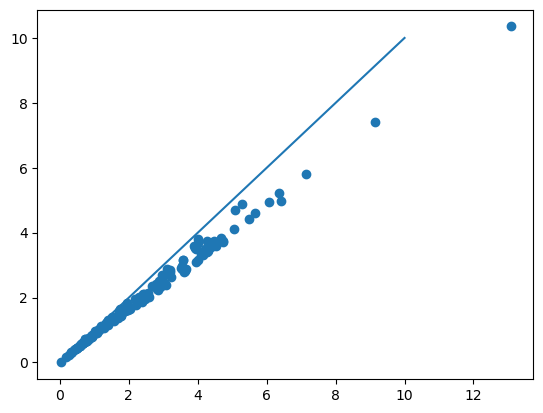

In [11]:
plt.scatter(comb['ObsLum'], [L.nominal_value for L in Lobs_calc])
plt.plot([0,10], [0,10])

In [12]:
# MCMC: L_o=(L_c - b)/m 
# change to L_o=(L500-b)/m
L_obs_data = comb['ObsLum']
L_obs_var=[L.std_dev for L in Lobs_calc]
#L_cor=comb['LumCor']
L500=comb['L500']

Text(0, 0.5, 'L500')

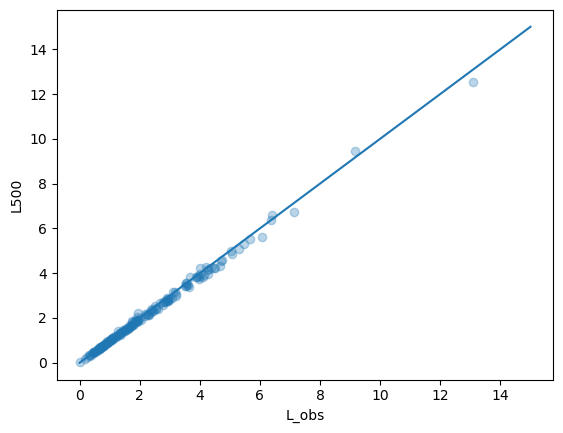

In [13]:
plt.scatter(L_obs_data, L500, alpha=0.3)
plt.plot(np.linspace(0,15), np.linspace(0,15))
plt.xlabel('L_obs')
plt.ylabel('L500')

In [14]:
def log_lik(p0, L_c, obs, var):
    m=p0[0]
    if np.abs(m)<0.00001:
        return -np.inf
    b=p0[1]
    if np.abs(m)>10 or np.abs(b)>10:
        return -np.inf
    pred=(L_c-b)/m
    return -1*chi_squared(pred, obs, var)/2

In [15]:
p0=[1, 0]
log_lik(p0, L500, L_obs_data, np.array(L_obs_var))

-23.439121240851986

In [16]:
ndim=2
nwalkers = 32
guess=(1, 0)
p0 = guess+np.random.normal(scale=0.1, size=(nwalkers, ndim))
p0

array([[ 1.10236313, -0.01533566],
       [ 1.03007671,  0.07078492],
       [ 1.06883199, -0.00127653],
       [ 1.00412312,  0.00723812],
       [ 0.86958416,  0.00397112],
       [ 1.05777166,  0.29072289],
       [ 0.9114969 ,  0.0194439 ],
       [ 1.05016136, -0.10536224],
       [ 0.80922007, -0.10696931],
       [ 1.00446601, -0.12869839],
       [ 0.86193095,  0.00526945],
       [ 1.08874665, -0.01244438],
       [ 1.17601257, -0.06127578],
       [ 1.00803865, -0.03643495],
       [ 1.04725869,  0.16159232],
       [ 1.20419415, -0.19755307],
       [ 0.92811814, -0.06108853],
       [ 1.1446874 ,  0.11426934],
       [ 0.86381708, -0.07855684],
       [ 0.78570839,  0.02384022],
       [ 0.97689606,  0.02662878],
       [ 1.13268166,  0.05631843],
       [ 0.87933869,  0.25081918],
       [ 1.01563414, -0.08165093],
       [ 1.00759862, -0.27909721],
       [ 1.06952516, -0.14648166],
       [ 0.93380002,  0.04684788],
       [ 1.01331047, -0.03159403],
       [ 1.05765722,

In [17]:
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_lik, args=[L500, L_obs_data, np.array(L_obs_var)])

In [18]:
state = sampler.run_mcmc(p0, 100, progress=True)
sampler.reset()

100%|████████████████████████████████████████| 100/100 [00:00<00:00, 142.16it/s]


In [19]:
sampler.run_mcmc(state, 5000, progress=True)

100%|██████████████████████████████████████| 5000/5000 [00:34<00:00, 144.39it/s]


State([[ 9.84035310e-01 -2.16796169e-04]
 [ 9.74589549e-01  9.50228878e-03]
 [ 9.75469198e-01  6.59678120e-03]
 [ 9.75135244e-01  4.96860067e-03]
 [ 9.70922104e-01  9.84265148e-03]
 [ 9.70358940e-01  6.21420324e-03]
 [ 9.78800708e-01  8.88786215e-04]
 [ 9.78457261e-01  5.87710561e-03]
 [ 9.67795051e-01  8.77220533e-03]
 [ 9.73785525e-01  5.37459243e-03]
 [ 9.64355760e-01  1.46874010e-02]
 [ 9.73383887e-01  6.40248406e-03]
 [ 9.63554656e-01  1.26421388e-02]
 [ 9.70758117e-01  5.11866762e-03]
 [ 9.72867635e-01  1.03547198e-02]
 [ 9.71971014e-01  5.39836609e-03]
 [ 9.78724852e-01 -2.92653347e-03]
 [ 9.72542556e-01  6.14639936e-03]
 [ 9.65842669e-01  1.28373464e-02]
 [ 9.67974376e-01  2.38921297e-03]
 [ 9.70626306e-01  1.04504341e-02]
 [ 9.69941466e-01  5.17589522e-03]
 [ 9.63559495e-01  6.95807436e-03]
 [ 9.82415588e-01  6.19464245e-03]
 [ 9.85386479e-01 -7.66101477e-03]
 [ 9.74543687e-01  5.94043152e-03]
 [ 9.79635636e-01  5.18198500e-03]
 [ 9.85451565e-01 -2.83237809e-03]
 [ 9.74667989e

In [20]:
flat_samples = sampler.get_chain(flat=True)
print(flat_samples.shape)

(160000, 2)


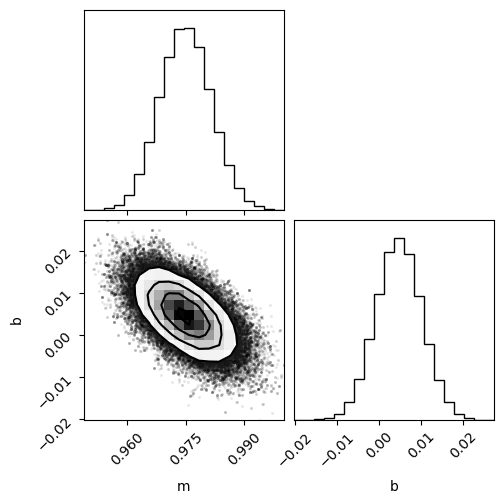

In [21]:
fig = corner.corner(flat_samples, labels=['m', 'b']) 

In [22]:
tau = sampler.get_autocorr_time()
print(tau)

[33.58247435 32.99127957]


In [23]:
np.median(flat_samples[:,0]), np.median(flat_samples[:,1])

(0.9748502128787027, 0.0047169529377331385)

In [24]:
m_err=np.var(flat_samples[:,0]) # var=mean((p-pmean)**2)
m_err

4.2443679999718053e-05

In [25]:
b_err=np.var(flat_samples[:,1])
b_err

2.9934387010787006e-05

In [26]:
m_uf=ufloat(np.median(flat_samples[:,0]), np.var(flat_samples[:,0]))
b_uf=ufloat(np.median(flat_samples[:,1]), np.var(flat_samples[:,1]))

m_uf, b_uf # uncertainty too small??

(0.9748502128787027+/-4.2443679999718053e-05,
 0.0047169529377331385+/-2.9934387010787006e-05)

In [27]:
# get L500 based on this relationship that we found
L_obs_uf=unp.uarray(comb['ObsLum'], [L.std_dev for L in Lobs_calc])

L500_pred=m_uf*L_obs_uf+b_uf

In [28]:
L500_uf=unp.uarray(comb['L500'], [L.std_dev for L in L500_pred])
L500_uf

array([0.846881+/-0.13670661127586403, 1.809494+/-0.21162744764251581,
       1.086002+/-0.08642763071422299, 1.236332+/-0.12415974419406967,
       2.827248+/-0.31397369127701974, 2.872451+/-0.2846928024932828,
       0.49467+/-0.043137278608052075, 2.164603+/-0.3071476086492964,
       1.404549+/-0.16384221676723312, 1.253723+/-0.09262340568063253,
       5.100085+/-0.1525752289612248, 2.734146+/-0.2281371573447247,
       1.437223+/-0.07297288054497619, 1.460216+/-0.08604661001887752,
       0.491051+/-0.03988704947493315, 0.181484+/-0.013431827398215605,
       0.467516+/-0.041164577179740904, 0.763259+/-0.055260683433402485,
       2.010759+/-0.26658097701730127, 4.237381+/-0.412515887009369,
       1.768408+/-0.24935542674647015, 0.561478+/-0.06529351707216095,
       0.669697+/-0.08461260949693022, 0.334315+/-0.14423531584437232,
       1.027456+/-0.08368238134632518, 3.815928+/-0.1335466211442247,
       0.593611+/-0.05293966806019749, 1.467361+/-0.0960029809982796,
       3.81

In [29]:
# grab predicted L errs
L_errs = [L.std_dev for L in L500_pred]
len(L_errs)

173

In [30]:
dict_name_err = dict(zip(comb['OName'], L_errs))

In [31]:
dict_name_err['RXCJ0011.3-2851']

0.08642763071422299

In [32]:
import pickle
with open('data/REFLEX_lowz_errs.p', 'wb') as fp:
    pickle.dump(dict_name_err, fp)

In [33]:
dict_name_err

{'RXCJ0003.8+0203': 0.13670661127586403,
 'RXCJ0006.0-3443': 0.21162744764251581,
 'RXCJ0011.3-2851': 0.08642763071422299,
 'RXCJ0013.6-1930': 0.12415974419406967,
 'RXCJ0014.3-6604': 0.31397369127701974,
 'RXCJ0020.7-2542': 0.2846928024932828,
 'RXCJ0025.5-3302': 0.043137278608052075,
 'RXCJ0027.3-5015': 0.3071476086492964,
 'RXCJ0028.6-2338': 0.16384221676723312,
 'RXCJ0034.6-0208': 0.09262340568063253,
 'RXCJ0041.8-0918': 0.1525752289612248,
 'RXCJ0042.1-2832': 0.2281371573447247,
 'RXCJ0056.3-0112': 0.07297288054497619,
 'RXCJ0102.7-2152': 0.08604661001887752,
 'RXCJ0108.8-1524': 0.03988704947493315,
 'RXCJ0110.0-4555': 0.013431827398215605,
 'RXCJ0115.2+0019': 0.041164577179740904,
 'RXCJ0120.9-1351': 0.055260683433402485,
 'RXCJ0145.0-5300': 0.26658097701730127,
 'RXCJ0145.2-6033': 0.412515887009369,
 'RXCJ0206.4-1453': 0.24935542674647015,
 'RXCJ0229.3-3332': 0.06529351707216095,
 'RXCJ0236.6-1923': 0.08461260949693022,
 'RXCJ0311.4-2653': 0.14423531584437232,
 'RXCJ0314.3-4525'

In [34]:
comb['OName']

0      RXCJ0003.8+0203
1      RXCJ0006.0-3443
2      RXCJ0011.3-2851
3      RXCJ0013.6-1930
4      RXCJ0014.3-6604
            ...       
168    RXCJ2344.2-0422
169    RXCJ2347.7-2808
170    RXCJ2354.2-1024
171    RXCJ2357.0-3445
172    RXCJ2359.3-6042
Name: OName, Length: 173, dtype: object